### **Nama: Andika Dinata**

### **NIM: 123140096**




### Memuat model pretrain

In [4]:
from gensim.models import KeyedVectors

# !pip install numpy matplotlib scikit-learn gensim
# !wget -c https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.vec.gz
model = KeyedVectors.load_word2vec_format("cc.id.300.vec.gz", binary=False)
print("Model dimuat. Dimensi vektor:", model.vector_size)

Model dimuat. Dimensi vektor: 300


## 1. One-Hot Encoding & Keterbatasannya

In [5]:
import numpy as np

vocab = ["dokter", "perawat", "matahari", "bulan", "kursi"]
word_to_id = {kata: i for i, kata in enumerate(vocab)}

def one_hot(kata, vocab, word_to_id):
    """Mengembalikan vektor one-hot untuk sebuah kata."""
    vektor = np.zeros(len(vocab))
    vektor[word_to_id[kata]] = 1
    return vektor

# (a) Tampilkan vektor one-hot untuk setiap kata
for kata in vocab:
    print(f"{kata:<12} -> {one_hot(kata, vocab, word_to_id)}")

dokter       -> [1. 0. 0. 0. 0.]
perawat      -> [0. 1. 0. 0. 0.]
matahari     -> [0. 0. 1. 0. 0.]
bulan        -> [0. 0. 0. 1. 0.]
kursi        -> [0. 0. 0. 0. 1.]


In [6]:
def cosine_similarity(a, b):
    """Kemiripan kosinus: (a.b) / (||a|| . ||b||)."""
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# (b) Matriks kemiripan kosinus 5x5
matriks = np.zeros((len(vocab), len(vocab)))
for i, kata_i in enumerate(vocab):
    for j, kata_j in enumerate(vocab):
        v_i = one_hot(kata_i, vocab, word_to_id)
        v_j = one_hot(kata_j, vocab, word_to_id)
        matriks[i, j] = cosine_similarity(v_i, v_j)

import pandas as pd
df_matriks = pd.DataFrame(matriks, index=vocab, columns=vocab)
df_matriks

,dokter,perawat,matahari,bulan,kursi
dokter,1.0,0.0,0.0,0.0,0.0
perawat,0.0,1.0,0.0,0.0,0.0
matahari,0.0,0.0,1.0,0.0,0.0
bulan,0.0,0.0,0.0,1.0,0.0
kursi,0.0,0.0,0.0,0.0,1.0


### (c) Jawaban Analisis Soal 1

- Mengapa semua kemiripan antar kata berbeda bernilai 0.0?
- Apa implikasinya terhadap model ML yang menerima input one-hot?
- Pasangan kata mana yang seharusnya lebih mirip secara semantik, dan mengapa one-hot tidak bisa menangkap ini?

Menurut saya, semua nilai kemiripan kosinus menjadi 0.0 karena pada representasi one-hot, setiap kata hanya memiliki satu nilai 1, tetapi posisinya berbeda untuk setiap kata. Jadi, ketika dua kata yang berbeda dibandingkan, tidak ada posisi yang sama-sama bernilai 1 sehingga hasil dot product-nya adalah 0.

Kekurangan dari one-hot adalah model tidak bisa langsung mengetahui hubungan atau kemiripan makna antar kata. Misalnya, kata "dokter" dan "perawat" seharusnya memiliki hubungan karena sama-sama berkaitan dengan profesi medis. Begitu juga dengan "matahari" dan "bulan" yang sama-sama merupakan benda langit. Namun, pada one-hot, kata-kata tersebut hanya dianggap sebagai identitas yang berbeda berdasarkan posisi indeksnya, bukan berdasarkan maknanya.

Akibatnya, model machine learning harus mempelajari hubungan antar kata dari dataset. Hal ini bisa membuat model membutuhkan data yang lebih banyak dan juga berisiko menghasilkan generalisasi yang kurang baik.


## 2. Word Embeddings: Vektor Dense & Kemiripan Semantik

In [7]:
# (a) 5 kata paling mirip untuk setiap kata
for kata in ["dokter", "matahari", "kursi"]:
    print(f"\n5 kata paling mirip dengan '{kata}':")
    for kata_mirip, skor in model.most_similar(kata, topn=5):
        print(f"  {kata_mirip:<16} {skor:.4f}")


5 kata paling mirip dengan 'dokter':
  dokter.Dokter    0.7709
  dokternya        0.7663
  Dokter           0.7634
  dokterdokter     0.7587
  dokter-          0.7578

5 kata paling mirip dengan 'matahari':
  matahri          0.7941
  mataharinya      0.7838
  matahari.        0.7411
  Matahari         0.7276
  matahar          0.7268

5 kata paling mirip dengan 'kursi':
  kursinya         0.7443
  kursi-kursi      0.7327
  kursi-           0.7183
  kursi2           0.7170
  Kursi            0.7095


In [8]:
# (b) Perbandingan numerik
sim_dokter_perawat = model.similarity("dokter", "perawat")
sim_dokter_kursi = model.similarity("dokter", "kursi")

print(f"sim(dokter, perawat) = {sim_dokter_perawat:.4f}")
print(f"sim(dokter, kursi)   = {sim_dokter_kursi:.4f}")

sim(dokter, perawat) = 0.6386
sim(dokter, kursi)   = 0.1990


### (c) Jawaban Analisis Soal 2

- Apakah "presiden" lebih dekat ke "indonesia" atau ke "musik"?
- Bandingkan secara eksplisit dengan hasil Soal 1 — apa yang berubah?
- Bagaimana embeddings mengatasi keterbatasan ortogonalitas one-hot?

Menurut saya, "dokter" akan lebih dekat dengan "perawat" daripada dengan "kursi" karena dokter dan perawat sama-sama berkaitan dengan profesi medis, sedangkan kursi tidak memiliki hubungan dengan konteks tersebut.

Hal ini berbeda dengan hasil pada Soal 1, di mana semua pasangan kata memiliki nilai kemiripan kosinus 0.0 karena representasi one-hot hanya menunjukkan identitas setiap kata dan tidak menyimpan informasi tentang maknanya.

Word embedding dapat mengatasi masalah tersebut karena setiap kata direpresentasikan dalam bentuk vektor yang lebih kecil dan nilainya dipelajari berdasarkan konteks kemunculan kata dalam kalimat.

Jadi, kata-kata yang sering muncul dalam konteks yang mirip akan memiliki posisi vektor yang lebih dekat. Dengan begitu, embedding bisa membantu model memahami hubungan atau kemiripan makna antar kata dari data, sedangkan one-hot tidak bisa melakukan hal tersebut karena setiap kata hanya dibedakan berdasarkan indeksnya.


## 3. Analogi Vektor dalam Bahasa Indonesia

In [9]:
# (a) raja - pria + wanita
hasil_a = model.most_similar(positive=["wanita", "raja"], negative=["pria"], topn=3)
print("raja - pria + wanita =")
for kata, skor in hasil_a:
    print(f"  {kata:<16} {skor:.4f}")

# (b) jepang - asia + eropa
hasil_b = model.most_similar(positive=["eropa", "jepang"], negative=["asia"], topn=3)
print("\njepang - asia + eropa =")
for kata, skor in hasil_b:
    print(f"  {kata:<16} {skor:.4f}")

# (c) jakarta - indonesia + jepang
hasil_c = model.most_similar(positive=["jepang", "jakarta"], negative=["indonesia"], topn=3)
print("\njakarta - indonesia + jepang =")
for kata, skor in hasil_c:
    print(f"  {kata:<16} {skor:.4f}")


raja - pria + wanita =
  kerajaan         0.6868
  raja-raja        0.6827
  ratu             0.6800

jepang - asia + eropa =
  jepang.          0.6176
  Jepang           0.6075
  jepangnya        0.5855

jakarta - indonesia + jepang =
  jakarta.         0.5178
  kejakarta        0.5002
  dijakarta        0.4991


### Jawaban Analisis Soal 3

- Apakah ketiga analogi menghasilkan kata yang masuk akal?
- Jika hasilnya tidak sempurna, hipotesiskan mengapa (bias korpus, frekuensi kata, ambiguitas, dsb.)

Dari ketiga analogi, hanya (a) yang cukup mendekati harapan, karena "ratu" muncul di top 3, meski bukan peringkat pertama. Analogi (b) dan (c) gagal total, hasilnya justru variasi morfologis dari kata input sendiri, seperti "jepang.", "Jepang", "jepangnya" atau "jakarta.", "kejakarta", "dijakarta", bukan kata yang diharapkan.

Ini terjadi karena fastText membentuk vektor berdasarkan subword karakter, sehingga kata dengan banyak karakter mirip. beda tanda baca, kapitalisasi, atau imbuhan dianggap sangat mirip walau sebenarnya kata yang sama.

Ini juga menandakan korpus pelatihan kurang bersih, banyak varian tanda baca ikut jadi entri kosakata terpisah dan mendominasi hasil pencarian.

In [10]:
# Bonus (d): Analogi kreatif buatan sendiri
hasil_bonus = model.most_similar(positive=["pria", "ibu"], negative=["wanita"], topn=3)
print("ibu - wanita + pria =")
for kata, skor in hasil_bonus:
    print(f"  {kata:<16} {skor:.4f}")

ibu - wanita + pria =
  ayah             0.7650
  Ibu              0.6590
  bapak            0.6222


### Jawaban Bonus (d) Soal 3

Saya memilih analogi "ibu - wanita + pria" karena menguji relasi gender dalam konteks keluarga, mirip pola raja-ratu yang sudah diuji sebelumnya.

Analogi ini berhasil dengan baik, terbukti kata "ayah" muncul sebagai hasil teratas dengan skor 0.7650, bahkan lebih tinggi dari skor tertinggi pada analogi raja-ratu.

Ini menunjukkan model menangkap relasi gender dalam konteks keluarga dengan sangat kuat, kemungkinan karena kata "ibu", "ayah", dan "bapak" sangat sering muncul berdampingan dalam berbagai konteks kalimat sehari-hari di korpus pelatihan.

## 4. Visualisasi Ruang Vektor Kata Indonesia

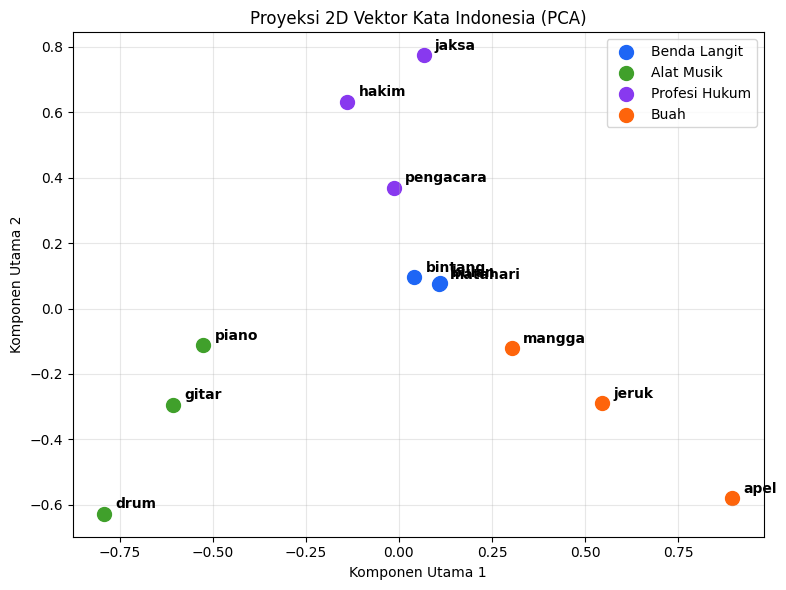

In [11]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

kata_pilihan = [
    "matahari", "bulan", "bintang",
    "gitar", "piano", "drum",
    "pengacara", "hakim", "jaksa",
    "apel", "mangga", "jeruk",
]

kelompok = {
    "matahari": "Benda Langit", "bulan": "Benda Langit", "bintang": "Benda Langit",
    "gitar": "Alat Musik", "piano": "Alat Musik", "drum": "Alat Musik",
    "pengacara": "Profesi Hukum", "hakim": "Profesi Hukum", "jaksa": "Profesi Hukum",
    "apel": "Buah", "mangga": "Buah", "jeruk": "Buah",
}

warna = {
    "Benda Langit": "#1e66f5", "Alat Musik": "#40a02b",
    "Profesi Hukum": "#8839ef", "Buah": "#fe640b",
}

# Ekstrak vektor & reduksi dimensi
vektor = np.array([model[k] for k in kata_pilihan])
pca = PCA(n_components=2)
koordinat_2d = pca.fit_transform(vektor)

# Plot
plt.figure(figsize=(8, 6))
sudah_label = set()
for i, kata in enumerate(kata_pilihan):
    k = kelompok[kata]
    lbl = k if k not in sudah_label else ""
    sudah_label.add(k)
    plt.scatter(koordinat_2d[i, 0], koordinat_2d[i, 1],
                c=warna[k], s=100, label=lbl)
    plt.annotate(kata, (koordinat_2d[i, 0], koordinat_2d[i, 1]),
                 textcoords="offset points", xytext=(8, 4),
                 fontsize=10, fontweight="bold")
plt.title("Proyeksi 2D Vektor Kata Indonesia (PCA)")
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("visualisasi_embeddings.png", dpi=150)
plt.show()

### (b) Jawaban Analisis Soal 4

- Apakah kluster yang terbentuk sesuai intuisi Anda?
- Kata mana yang paling "tercampur" atau berjauhan dari kelompoknya?
- Mengapa menurut Anda hal tersebut terjadi?

Klaster yang terbentuk secara umum adalah keempat kelompok Benda Langit, Alat Musik, Profesi Hukum, Buah yang menempati area yang terpisah jelas satu sama lain di ruang 2D, tanpa ada percampuran antar kelompok.

Kelompok Benda Langit (matahari, bulan, bintang) adalah yang paling rapat, ketiga titiknya nyaris berhimpitan, menunjukkan kemiripan makna yang sangat kuat.

Namun di dalam kelompok Alat Musik dan Buah, jarak antaranggota justru cukup lebar, "drum" terpisah cukup jauh dari "piano" dan "gitar", begitu juga "apel" yang berjauhan dari "mangga" dan "jeruk".

Hal ini kemungkinan terjadi karena "drum" dan "apel" punya konteks penggunaan yang lebih beragam. drum bisa merujuk pada wadah/tong, apel juga bisa berarti "upacara/apel pagi" dalam bahasa Indonesia. Sehingga vektornya bercampur dengan makna lain di luar konteks kelompok aslinya dan menggeser posisinya dalam ruang embedding.

## 5. Polisemi: Limitasi Embeddings Statis

In [12]:
# (a) 5 kata terdekat dari 'tahu'
print("5 kata paling mirip dengan 'tahu':")
for kata, skor in model.most_similar("tahu", topn=5):
    print(f"  {kata:<16} {skor:.4f}")


5 kata paling mirip dengan 'tahu':
  tau              0.8327
  mengetahui       0.7840
  mengerti         0.7286
  yakin            0.7152
  tahu.Apa         0.7116


### (b) Jawaban Analisis Soal 5

- Apakah 5 kata terdekat mencerminkan kedua makna "tahu" (makanan & mengetahui), atau hanya salah satu?
- Makna mana yang cenderung terwakili? Mengapa?
- Mengapa ini menjadi keterbatasan fundamental embeddings statis?

Kelima kata terdekat dari "tahu" yaitu "tau", "mengetahui", "mengerti", "yakin", "tahu.Apa" seluruhnya mencerminkan makna verba mengetahui, tidak satu pun yang mengarah ke makna makanan dari kedelai.

Makna "mengetahui" jauh lebih dominan kemungkinan karena kata "tahu" sebagai kata kerja jauh lebih sering muncul dalam berbagai konteks kalimat sehari-hari dibanding "tahu" sebagai makanan.

Ini membuktikan keterbatasan fundamental embeddings statis. Karena setiap kata hanya diberi satu vektor tetap tanpa memandang konteks kalimatnya, makna yang lebih jarang muncul, dalam hal ini "tahu" sebagai makanan akan tenggelam sepenuhnya oleh makna yang lebih dominan, sehingga model tidak bisa membedakan kedua makna berbeda tersebut sama sekali.

### (c) Bonus: Contextual Embeddings dengan IndoBERT

In [13]:
# Bonus: jalankan hanya jika transformers & torch tersedia
from transformers import AutoTokenizer, AutoModel
import torch

name = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(name)
model_bert = AutoModel.from_pretrained(name)
model_bert.eval()

def vektor_kata(kalimat, kata):
    """Vektor kontekstual dari hidden state BERT."""
    enc = tokenizer(kalimat, return_tensors="pt")
    with torch.no_grad():
        out = model_bert(**enc)
    hidden = out.last_hidden_state[0]
    ids = tokenizer.encode(kata, add_special_tokens=False)
    pos = (enc["input_ids"][0] == ids[0]).nonzero()[0].item()
    return hidden[pos]

s1 = "Ibu membeli tahu goreng di pasar."
s2 = "Saya tahu jawaban soal itu."

v1 = vektor_kata(s1, "tahu")
v2 = vektor_kata(s2, "tahu")

cos = torch.nn.functional.cosine_similarity(v1.unsqueeze(0), v2.unsqueeze(0)).item()
print(f"Kemiripan vektor 'tahu' antar dua konteks: {cos:.4f}")


config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Kemiripan vektor 'tahu' antar dua konteks: 0.3459


### Jawaban Bonus Soal 5(c)

- Seberapa berbeda vektor kontekstual "tahu" di dua kalimat tersebut?
- Bagaimana hal ini membuktikan keunggulan contextual embeddings?

Vektor kontekstual "tahu" dari IndoBERT pada dua kalimat berbeda menghasilkan kemiripan kosinus hanya 0.3459, jauh dari 1.0, yang berarti kedua vektor tersebut cukup berbeda secara signifikan.

Ini sangat kontras dengan fastText, yang selalu memberikan vektor identik untuk kata "tahu" berapa pun konteks kalimatnya, sehingga tidak bisa membedakan antara makna "tahu" sebagai makanan dan "tahu" sebagai kata kerja mengetahui.

Hasil ini membuktikan keunggulan contextual embeddings. Karena IndoBERT menghasilkan representasi kata berdasarkan konteks kalimat di sekitarnya, model mampu menangkap perbedaan makna kata yang sama (polisemi).

## 6. Refleksi: Evolusi Arsitektur Sekuensial

### (a) Vanishing Gradient & Mekanisme LSTM

- Mengapa vanishing gradient muncul pada RNN (kaitkan dengan propagasi gradien melalui banyak langkah waktu)?
- Bagaimana LSTM mengatasinya melalui forget gate, input gate, dan output gate?
- Sertakan analogi sederhana untuk memperjelas.

Menurut saya, vanishing gradient terjadi pada RNN karena ketika model belajar dari data yang memiliki banyak langkah, informasi dari bagian awal bisa semakin lama semakin berkurang. Akibatnya, RNN menjadi sulit mengingat informasi yang sudah muncul sebelumnya.

LSTM mengatasi masalah tersebut dengan menggunakan beberapa gerbang yang membantu memilih informasi mana yang perlu disimpan dan mana yang bisa dibuang. Jadi, informasi penting bisa tetap diingat lebih lama.

Kalau diibaratkan seperti buku catatan, RNN biasa bisa saja melupakan catatan yang sudah lama ditulis. Sedangkan LSTM seperti memiliki seseorang yang membantu menandai informasi penting supaya tidak mudah hilang.

### (b) RNN/LSTM vs Transformer: Trade-off

- Satu contoh konkret skenario di mana RNN/LSTM mungkin lebih unggul/praktis daripada Transformer.
- Alasannya, merujuk pada sifat arsitektur keduanya (misalnya: komputasi, memori, panjang sekuens, ketersediaan data).

RNN/LSTM lebih unggul untuk pemrosesan data streaming real-time dengan sumber daya terbatas, misalnya prediksi ketikan pada keyboard ponsel atau sensor IoT, karena bisa memproses input satu langkah waktu secara langsung tanpa menunggu seluruh sekuens tersedia.

Transformer sebaliknya butuh seluruh sekuens sekaligus karena self-attention menghitung relasi antar semua token, sedangkan RNN/LSTM tumbuh linear dan lebih hemat memori. Karena itu, untuk sekuens sangat panjang atau perangkat dengan daya komputasi terbatas, RNN/LSTM tetap jadi pilihan yang lebih praktis.